## 1. La imagen como matriz

Una imagen MNIST en escala de grises es una matriz de $28 	\times 28$. Cada entrada es una intensidad entre 0 y 255. La computadora no recibe el concepto de "tres": recibe números organizados en una matriz.

Etiqueta: 3
Forma: (28, 28)
Intensidad mínima y máxima: 0 255


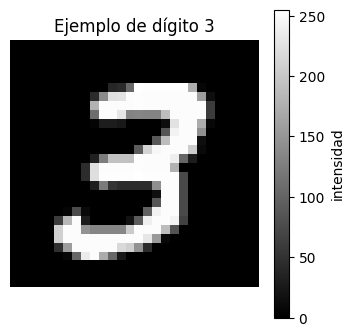

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

(x_train, y_train), _ = tf.keras.datasets.mnist.load_data()

indice = np.flatnonzero(y_train == 3)[0]
imagen = x_train[indice]

print("Etiqueta:", y_train[indice])
print("Forma:", imagen.shape)
print("Intensidad mínima y máxima:", imagen.min(), imagen.max())

plt.figure(figsize=(4, 4))
plt.imshow(imagen, cmap="gray", vmin=0, vmax=255)
plt.title(f"Ejemplo de dígito {y_train[indice]}")
plt.colorbar(label="intensidad")
plt.axis("off")
plt.show()

In [ ]:
for row in imagen.astype(int):
    print(" ".join(f"{val:3}" for val in row))

  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0  38  43 105 255 253 253 253 253 253 174   6   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0  43 139 224 226 252 253 252 252 252 252 252 252 158  14   0   0   0   0   0
  0   0   0   0   0   0   0   0   0 178 252 252 252 252 253 252 252 252 252 252 252 252  59   0   0   0   0   0
  0   0   0   0   0   0   0   0   0 109 252 252 230 132 133 132 132 189 252 252 252 252  59   0   0   0 

## 2. Antes de deslizarlo: una multiplicación local

Un kernel toma una pequeña ventana de la imagen. Multiplicamos posición por posición y sumamos los productos. Hagámoslo primero con una región de $3 	\times 3$ y un kernel que responde a cambios de izquierda a derecha.

In [ ]:
region = np.array([
    [10, 20, 30],
    [10, 20, 30],
    [10, 20, 30],
], dtype="float32")

kernel_demo = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1],
], dtype="float32")

productos = region * kernel_demo
respuesta = productos.sum()

print("Región:")
print(region)
print("Kernel:")
print(kernel_demo)
print("Producto posición a posición:")
print(productos)
print("Suma de los productos:", respuesta)

Región:
[[10. 20. 30.]
 [10. 20. 30.]
 [10. 20. 30.]]
Kernel:
[[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]
Producto posición a posición:
[[-10.   0.  30.]
 [-10.   0.  30.]
 [-10.   0.  30.]]
Suma de los productos: 60.0


## 3. Deslizar el kernel por toda la imagen

Ahora repetimos esa multiplicación local en cada posición. Para conservar el tamaño de la imagen, agregamos un borde de ceros (*padding*). Esta versión trabaja con matrices 2D y kernels de dimensiones impares.

En las redes neuronales, esta operación suele llamarse convolución. Los frameworks aplican usualmente el producto sin voltear previamente el kernel (correlación cruzada), aunque conservan el nombre `Conv2D`.

In [ ]:
def aplicar_kernel(imagen, kernel):
    imagen = np.asarray(imagen, dtype="float32")
    kernel = np.asarray(kernel, dtype="float32")

    alto_kernel, ancho_kernel = kernel.shape
    pad_y = alto_kernel // 2
    pad_x = ancho_kernel // 2
    imagen_con_borde = np.pad(
        imagen,
        ((pad_y, pad_y), (pad_x, pad_x)),
        mode="constant",
    )

    respuesta = np.zeros_like(imagen, dtype="float32")

    for fila in range(imagen.shape[0]):
        for columna in range(imagen.shape[1]):
            ventana = imagen_con_borde[
                fila : fila + alto_kernel,
                columna : columna + ancho_kernel,
            ]
            respuesta[fila, columna] = np.sum(ventana * kernel)

    return respuesta


def visualizar_kernel(kernel, salida, nombre, respuesta_con_signo=False):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    max_kernel = max(float(np.max(np.abs(kernel))), 1.0)
    axes[0].imshow(kernel, cmap="coolwarm", vmin=-max_kernel, vmax=max_kernel)
    for fila in range(kernel.shape[0]):
        for columna in range(kernel.shape[1]):
            axes[0].text(
                columna,
                fila,
                f"{kernel[fila, columna]:g}",
                ha="center",
                va="center",
                color="black",
            )
    axes[0].set_title(f"Kernel: {nombre}")
    axes[0].set_xticks([])
    axes[0].set_yticks([])

    axes[1].imshow(imagen, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Imagen de entrada")
    axes[1].axis("off")

    if respuesta_con_signo:
        limite = max(float(np.max(np.abs(salida))), 1.0)
        axes[2].imshow(salida, cmap="seismic", vmin=-limite, vmax=limite)
        axes[2].set_title("Respuesta: positivo / negativo")
    else:
        axes[2].imshow(salida, cmap="gray", vmin=0, vmax=255)
        axes[2].set_title("Imagen resultante")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

## Kernel 1 · Identidad

El kernel identidad tiene un `1` en el centro y ceros alrededor. Cada píxel se multiplica por 1 y sus vecinos por 0: la imagen queda igual.

¿La salida es igual a la entrada? True


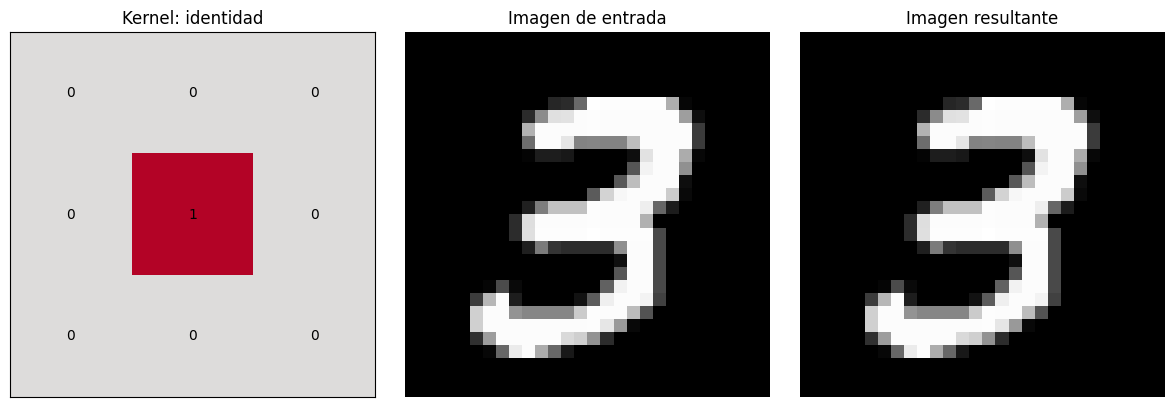

In [ ]:
kernel_identidad = np.array([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0],
], dtype="float32")

salida_identidad = aplicar_kernel(imagen, kernel_identidad)
print("¿La salida es igual a la entrada?", np.allclose(salida_identidad, imagen))
visualizar_kernel(kernel_identidad, salida_identidad, "identidad")

## Kernel 2 · Promedio (desenfoque)

El kernel de promedio asigna el mismo peso a los nueve píxeles de la ventana. Cada salida es el promedio local; los cambios bruscos se suavizan.

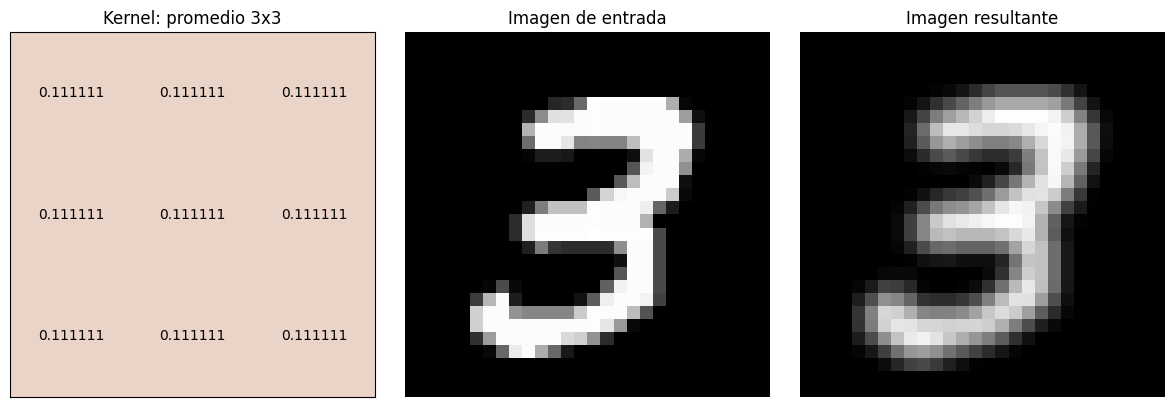

In [ ]:
kernel_promedio = np.ones((3, 3), dtype="float32") / 9
salida_promedio = aplicar_kernel(imagen, kernel_promedio)

visualizar_kernel(kernel_promedio, salida_promedio, "promedio 3x3")

## Kernel 3 · Borde vertical (Sobel $x$)

Este kernel compara intensidades a izquierda y derecha. Una respuesta grande aparece donde cambia la imagen en esa dirección, por lo que resalta principalmente **bordes verticales**.

Las respuestas pueden ser negativas o positivas: el signo distingue la dirección del cambio. Por eso la visualización usa un mapa divergente alrededor de cero.

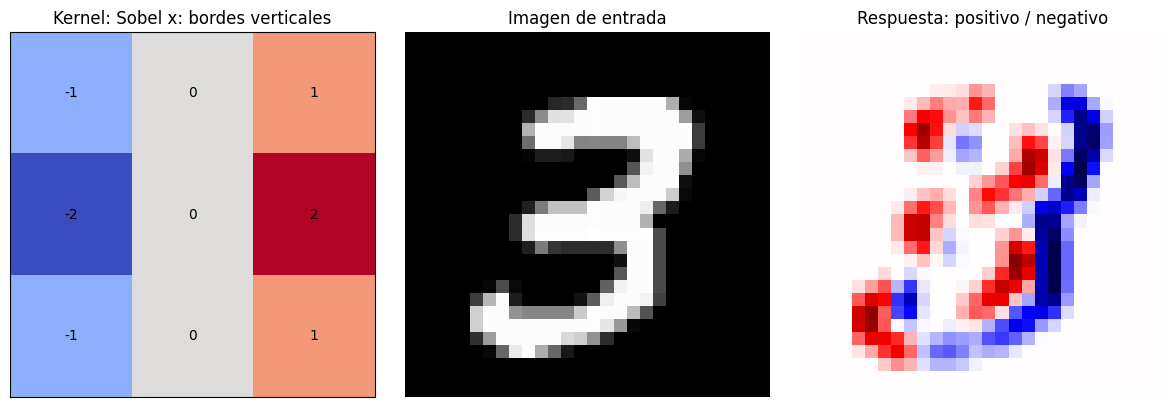

In [ ]:
kernel_sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1],
], dtype="float32")

salida_sobel_x = aplicar_kernel(imagen, kernel_sobel_x)
visualizar_kernel(
    kernel_sobel_x,
    salida_sobel_x,
    "Sobel x: bordes verticales",
    respuesta_con_signo=True,
)

## Kernel 4 · Borde horizontal (Sobel $y$)

Este kernel compara intensidades de arriba y abajo. Responde con fuerza a cambios en esa dirección y resalta principalmente **bordes horizontales**.

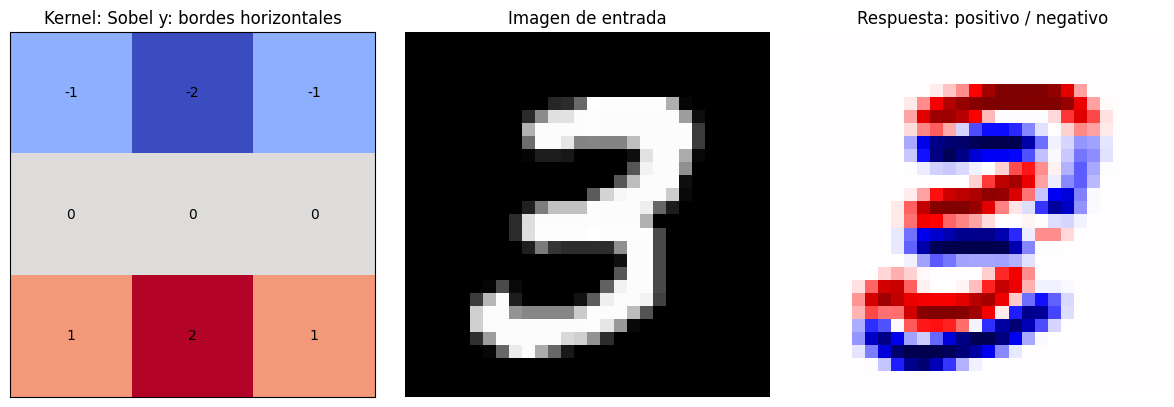

In [ ]:
kernel_sobel_y = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1],
], dtype="float32")

salida_sobel_y = aplicar_kernel(imagen, kernel_sobel_y)
visualizar_kernel(
    kernel_sobel_y,
    salida_sobel_y,
    "Sobel y: bordes horizontales",
    respuesta_con_signo=True,
)

## Combinar las dos direcciones

Los kernels Sobel $x$ y $y$ detectan cambios en direcciones diferentes. Podemos combinar sus respuestas para obtener una magnitud de borde, sin conservar el signo:

$$G = \sqrt{G_x^2 + G_y^2}$$

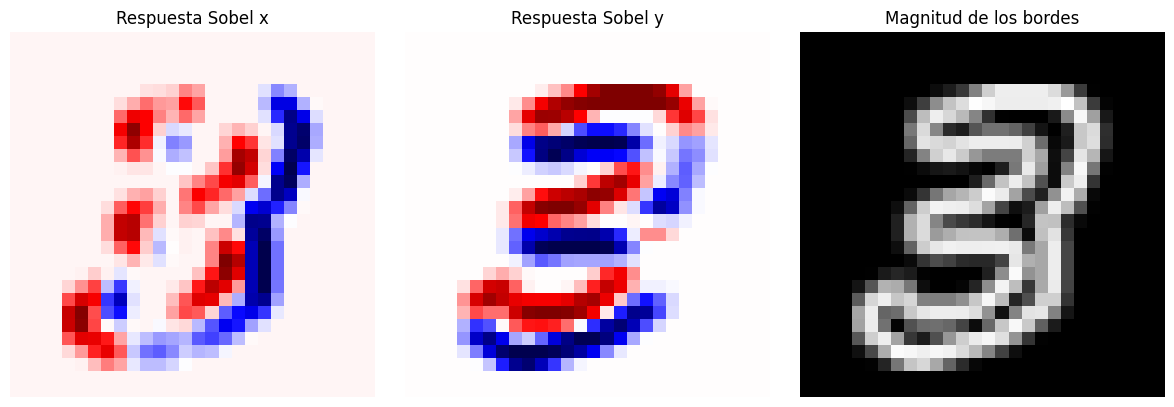

In [ ]:
magnitud_bordes = np.sqrt(salida_sobel_x ** 2 + salida_sobel_y ** 2)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(salida_sobel_x, cmap="seismic")
axes[0].set_title("Respuesta Sobel x")
axes[1].imshow(salida_sobel_y, cmap="seismic")
axes[1].set_title("Respuesta Sobel y")
axes[2].imshow(magnitud_bordes, cmap="gray")
axes[2].set_title("Magnitud de los bordes")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Cierre: ¿qué cambia en una CNN?

En esta inducción diseñamos los valores de cada kernel a mano y observamos qué patrón detectaba. En una red convolucional, `Conv2D` comienza con filtros y **aprende sus valores a partir de los datos**.

### Reto de exploración

Modifica los valores de un kernel de $3 \times 3$ para que responda a una diagonal. Aplícalo a la imagen y explica qué partes producen respuestas positivas y negativas.

En la clase 8 pasaremos de estos filtros manuales a filtros aprendidos con TensorFlow.